Generated 25920 frames across 72 sessions

DESCRIPTIVE STATISTICS
         session_id  distance_to_hazard      velocity  posture_class  \
count  25920.000000        25920.000000  25920.000000   25920.000000   
mean      35.500000            2.278571      0.370541       0.052083   
std       20.783006            0.589006      0.190292       0.222373   
min        0.000000            0.017670      0.000076       0.000000   
25%       17.750000            1.923722      0.234761       0.000000   
50%       35.500000            2.341199      0.334510       0.000000   
75%       53.250000            2.694748      0.476008       0.000000   
max       71.000000            4.091133      1.166824       2.000000   

       time_to_contact  hip_height_trend  head_zone_alignment  \
count     25920.000000      25920.000000         25920.000000   
mean          9.134071          0.410113             0.172309   
std          12.057506          0.113652             0.066094   
min           0.024086   

/tmp/ipykernel_16/249892144.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='risk_level', data=df, palette='viridis')


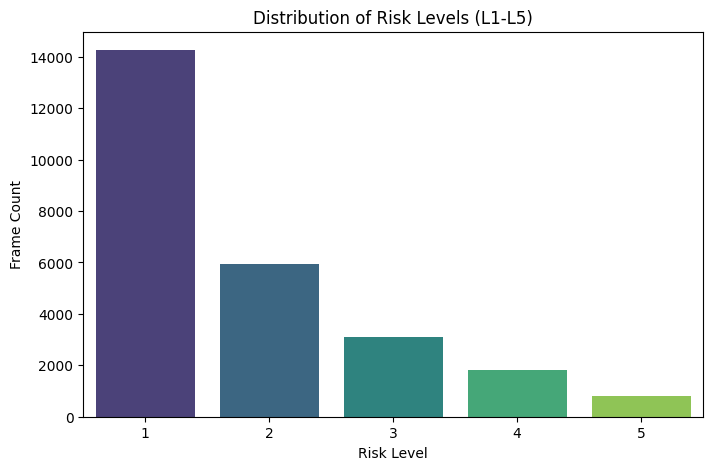

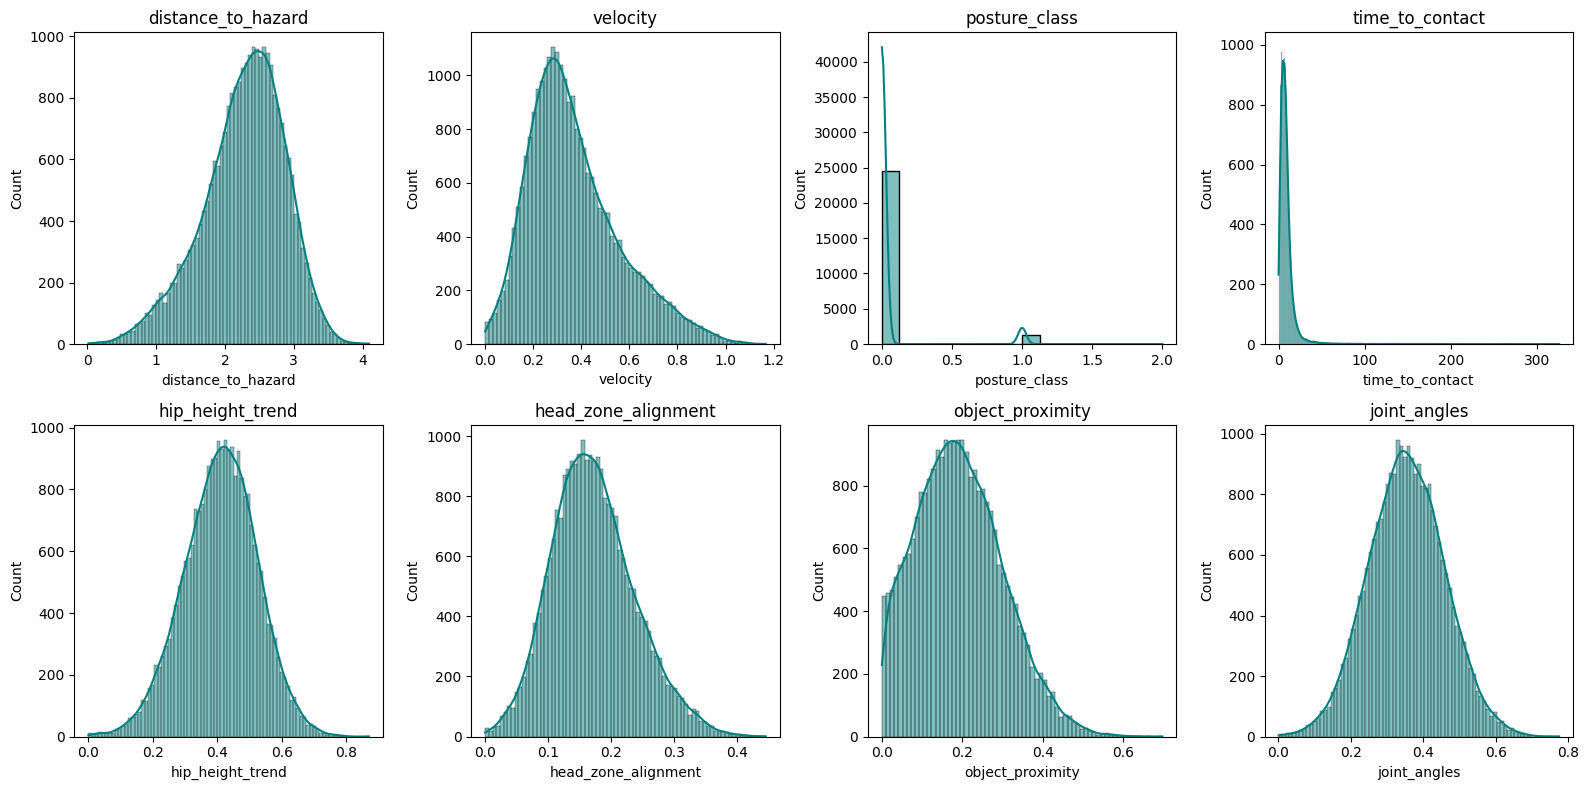


TRAIN / VALIDATION SPLIT
Train sessions: 50
Validation sessions: 22
Train frames: 18000
Validation frames: 7920
Training until validation scores don't improve for 50 rounds
[50]	valid_0's multi_logloss: 0.533723
[100]	valid_0's multi_logloss: 0.492948
[150]	valid_0's multi_logloss: 0.489913
[200]	valid_0's multi_logloss: 0.491503
Early stopping, best iteration is:
[152]	valid_0's multi_logloss: 0.489735


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


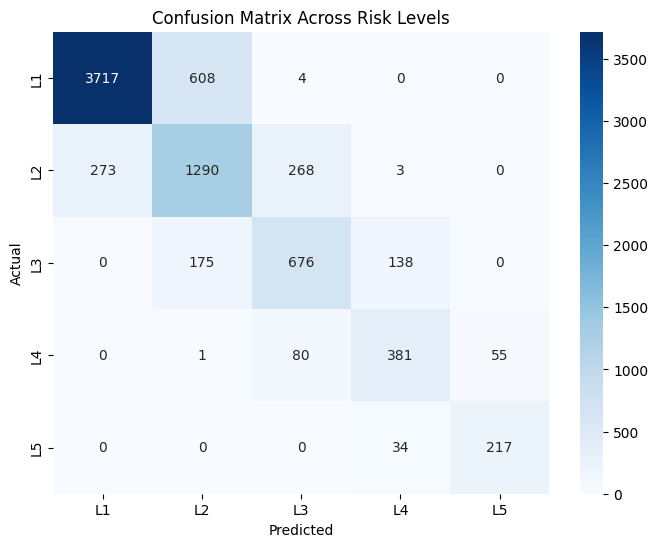

/tmp/ipykernel_16/249892144.py:133: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importance, y=feature_names, palette='viridis')


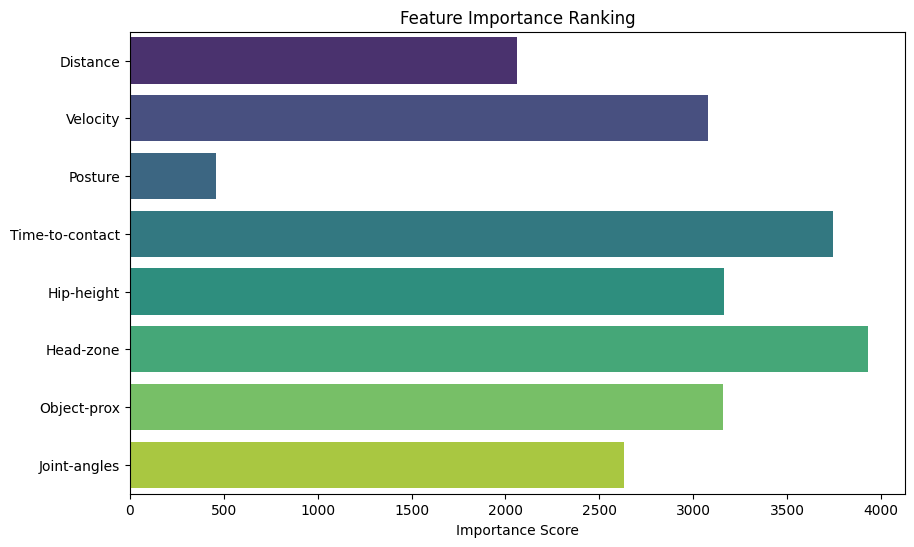

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut


PARAMETER SWEEP
   leaves    lr        f1
0      16  0.05  0.798388
1      16  0.10  0.793866
2      31  0.05  0.796931
3      31  0.10  0.792955
4      63  0.05  0.800771
5      63  0.10  0.793619
6     127  0.05  0.797114
7     127  0.10  0.797715


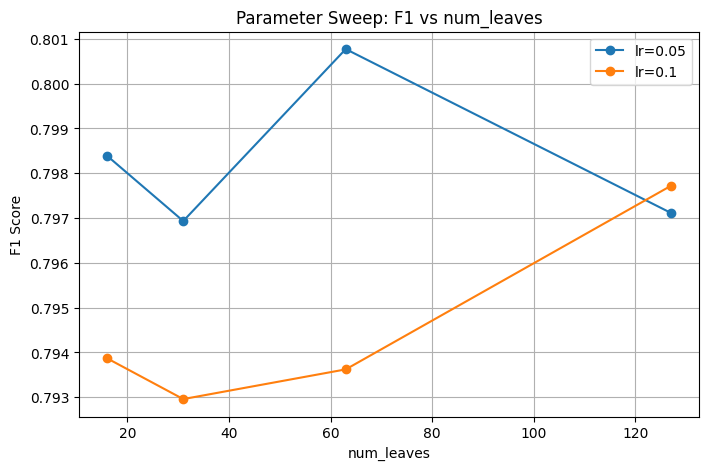


CLASSIFICATION REPORT
              precision    recall  f1-score   support

          L1      0.932     0.859     0.894      4329
          L2      0.622     0.703     0.660      1834
          L3      0.658     0.684     0.670       989
          L4      0.685     0.737     0.710       517
          L5      0.798     0.865     0.830       251

    accuracy                          0.793      7920
   macro avg      0.739     0.769     0.753      7920
weighted avg      0.805     0.793     0.798      7920


PROACTIVE GUARDIAN — RESULTS SUMMARY
Overall F1:              0.798
Safe class precision:    0.839
Safe class recall:       0.812
Alert class precision:   0.686
Alert class recall:      0.725


In [1]:
# ============================================================
# PROACTIVE GUARDIAN — ANALYSIS NOTEBOOK
# Author: Mamorobela Mahlatsi Suprise (202400251)
# Sol Plaatje University
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, f1_score
from sklearn.metrics import precision_score, recall_score

np.random.seed(42)
n = 25920
sessions = np.repeat(np.arange(72), n // 72)

# ----- Risk level drives the features (realistic simulation) -----
risk_level = np.random.choice([1, 2, 3, 4, 5], n, p=[0.55, 0.23, 0.12, 0.07, 0.03])

distance = np.abs(np.random.normal(3.0 - 0.4 * risk_level, 0.4, n))
velocity = np.abs(np.random.normal(0.1 + 0.15 * risk_level, 0.1, n))
posture = np.clip(np.random.normal(0.2 * risk_level, 0.3, n), 0, 3).astype(int)
time_to_contact = distance / (velocity + 0.01)
hip_height = np.abs(np.random.normal(0.5 - 0.05 * risk_level, 0.1, n))
head_zone = np.abs(np.random.normal(0.1 + 0.04 * risk_level, 0.05, n))
object_prox = np.abs(np.random.normal(0.1 + 0.05 * risk_level, 0.1, n))
joint_angles = np.abs(np.random.normal(0.3 + 0.03 * risk_level, 0.1, n))

df = pd.DataFrame({
    'session_id': sessions,
    'distance_to_hazard': distance,
    'velocity': velocity,
    'posture_class': posture,
    'time_to_contact': time_to_contact,
    'hip_height_trend': hip_height,
    'head_zone_alignment': head_zone,
    'object_proximity': object_prox,
    'joint_angles': joint_angles,
    'risk_level': risk_level
})

df.to_csv('features.csv', index=False)
print(f"Generated {n} frames across 72 sessions")
df.head()

# ----- Descriptive Statistics -----
print("\n" + "=" * 50)
print("DESCRIPTIVE STATISTICS")
print("=" * 50)
print(df.describe())

# ----- Risk Level Distribution -----
plt.figure(figsize=(8, 5))
sns.countplot(x='risk_level', data=df, palette='viridis')
plt.title('Distribution of Risk Levels (L1-L5)')
plt.xlabel('Risk Level')
plt.ylabel('Frame Count')
plt.show()

# ----- Feature Distributions -----
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
features = ['distance_to_hazard', 'velocity', 'posture_class',
            'time_to_contact', 'hip_height_trend', 'head_zone_alignment',
            'object_proximity', 'joint_angles']
for ax, feat in zip(axes.flatten(), features):
    sns.histplot(df[feat], ax=ax, kde=True, color='teal')
    ax.set_title(feat)
plt.tight_layout()
plt.show()

# ----- Train/Validation Split (Session Level) -----
X = df.drop(columns=['risk_level', 'session_id']).values
y = df['risk_level'].values - 1
groups = df['session_id'].values

unique_sessions = np.unique(groups)
train_sessions, val_sessions = train_test_split(unique_sessions, test_size=0.3, random_state=42)
train_mask = np.isin(groups, train_sessions)
val_mask = np.isin(groups, val_sessions)

print("\n" + "=" * 50)
print("TRAIN / VALIDATION SPLIT")
print("=" * 50)
print(f"Train sessions: {len(train_sessions)}")
print(f"Validation sessions: {len(val_sessions)}")
print(f"Train frames: {train_mask.sum()}")
print(f"Validation frames: {val_mask.sum()}")

# ----- Train the LightGBM Model -----
params = {
    'objective': 'multiclass',
    'num_class': 5,
    'num_leaves': 31,
    'max_depth': 6,
    'learning_rate': 0.05,
    'n_estimators': 400,
    'min_child_samples': 20,
    'feature_fraction': 0.9,
    'bagging_fraction': 0.8,
    'class_weight': 'balanced',
    'verbose': -1
}

model = lgb.LGBMClassifier(**params)
model.fit(
    X[train_mask], y[train_mask],
    eval_set=[(X[val_mask], y[val_mask])],
    callbacks=[lgb.early_stopping(50), lgb.log_evaluation(50)]
)

# ----- Confusion Matrix -----
y_pred = model.predict(X[val_mask])
cm = confusion_matrix(y[val_mask], y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['L1', 'L2', 'L3', 'L4', 'L5'],
            yticklabels=['L1', 'L2', 'L3', 'L4', 'L5'])
plt.title('Confusion Matrix Across Risk Levels')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ----- Feature Importance -----
importance = model.feature_importances_
feature_names = ['Distance', 'Velocity', 'Posture', 'Time-to-contact',
                 'Hip-height', 'Head-zone', 'Object-prox', 'Joint-angles']

plt.figure(figsize=(10, 6))
sns.barplot(x=importance, y=feature_names, palette='viridis')
plt.title('Feature Importance Ranking')
plt.xlabel('Importance Score')
plt.show()

# ----- Parameter Sweep -----
results = []
for leaves in [16, 31, 63, 127]:
    for lr in [0.05, 0.10]:
        m = lgb.LGBMClassifier(
            objective='multiclass', num_class=5,
            num_leaves=leaves, learning_rate=lr,
            n_estimators=400, class_weight='balanced', verbose=-1
        )
        m.fit(X[train_mask], y[train_mask])
        yp = m.predict(X[val_mask])
        f1 = f1_score(y[val_mask], yp, average='weighted')
        results.append({'leaves': leaves, 'lr': lr, 'f1': f1})

sweep_df = pd.DataFrame(results)
print("\n" + "=" * 50)
print("PARAMETER SWEEP")
print("=" * 50)
print(sweep_df)

plt.figure(figsize=(8, 5))
for lr in [0.05, 0.10]:
    subset = sweep_df[sweep_df['lr'] == lr]
    plt.plot(subset['leaves'], subset['f1'], marker='o', label=f'lr={lr}')
plt.title('Parameter Sweep: F1 vs num_leaves')
plt.xlabel('num_leaves')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)
plt.show()

# ----- Classification Report -----
print("\n" + "=" * 50)
print("CLASSIFICATION REPORT")
print("=" * 50)
print(classification_report(y[val_mask], y_pred,
                            target_names=['L1', 'L2', 'L3', 'L4', 'L5'],
                            digits=3))

# ----- Results Summary -----
overall_f1 = f1_score(y[val_mask], y_pred, average='weighted')
safe_precision = precision_score(y[val_mask], y_pred, labels=[0, 1], average='weighted')
safe_recall = recall_score(y[val_mask], y_pred, labels=[0, 1], average='weighted')
alert_precision = precision_score(y[val_mask], y_pred, labels=[2, 3, 4], average='weighted')
alert_recall = recall_score(y[val_mask], y_pred, labels=[2, 3, 4], average='weighted')

print("\n" + "=" * 50)
print("PROACTIVE GUARDIAN — RESULTS SUMMARY")
print("=" * 50)
print(f"Overall F1:              {overall_f1:.3f}")
print(f"Safe class precision:    {safe_precision:.3f}")
print(f"Safe class recall:       {safe_recall:.3f}")
print(f"Alert class precision:   {alert_precision:.3f}")
print(f"Alert class recall:      {alert_recall:.3f}")
print("=" * 50)